# Genetic algorithm on the Fidentis case

The BRKGA of [14](../math/14_genetic-algorithm.md) against the best dispatching rule and CP-SAT, its convergence, and
two Pareto fronts from NSGA-II over the same keys and decoder.

**Two instances** from `data/generator/fidentis.json` (10 orders, one printer, one mill, one oven, default
calendar):

- **fidentis**: two workers. The workers need more days for their work (12.2 calendar days) than the mill (9.5,
  running around the clock), but the mill's attended setups and removals wait for the shift, so both limit the plan.
- **balanced**: a third worker. Mill (9.5) and workers (8.1) need about the same number of days: no clear
  bottleneck.

Each with and without s-batches ([08](../math/08_serial-batches.md)). Objective: makespan. The computing cells store
their results in `notebooks/results/09/` and load them on the next run (recomputed when the parameters change or
with `RECOMPUTE = True`). Rebuild with `uv run python notebooks/build_09_ga.py`.

In [1]:
%matplotlib inline
import hashlib
import json
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

from simulation.model.schedule import Schedule
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.viz import plan_at, plot_days, plot_plan_state

from ga_runs import (CASES, FIDENTIS, FRONT_TIME, GA_GENERATIONS, RATES, RESCHED_PLANNERS, RESCHED_SEEDS, SETTINGS,
                     TIME_LIMIT, WINDOWS, cpsat_run, front_run, ga_run, instance, resched_run,
                     loads, rule_run)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "notebooks/results/09"
RECOMPUTE = False  # True: compute everything again (after a change of planners or decoder)
SEEDS = range(1, 7)
DIGEST = hashlib.sha256((FIDENTIS.model_dump_json() + repr((CASES, SETTINGS, TIME_LIMIT, FRONT_TIME, list(SEEDS))))
                        .encode()).hexdigest()[:12]
COLORS = {"best rule": "#2a78d6", "CP-SAT": "#eb6834", "GA": "#1baf7a", "GA no-delay": "#eda100",
          "GA greedy join": "#008300"}  # fixed order; slots 5 and 7 are the instances in figure 3
PLANNERS = list(COLORS)
DAY = 1440


def cached(name, compute, digest=DIGEST):
    # compute() as JSON in RESULTS/<name>.json: loaded if stored for the same parameters, else computed
    path = RESULTS / f"{name}.json"
    if not RECOMPUTE and path.exists() and (data := json.loads(path.read_text(encoding="utf-8")))["digest"] == digest:
        print(f"loaded {path.relative_to(ROOT)}")
        return data["value"]
    value = compute()
    RESULTS.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"digest": digest, "value": value}) + "\n", encoding="utf-8")
    return value

## 1. The two instances

Days a resource needs for its work alone (machines 24 h a day; workers 510 minutes per working day each, five
working days a week, given in calendar days).

In [2]:
for case in CASES:
    print(f"{case:9}", loads(instance(case, True)))

fidentis  {'oven': 0.5, 'mill': 9.5, 'print': 2.2, 'workers': 12.2}
balanced  {'oven': 0.5, 'mill': 9.5, 'print': 2.2, 'workers': 8.1}


## 2. Comparison at equal wall time

Per instance and variant: the best of the 15 rule plans (5 sequencing x 3 assignment variants), CP-SAT (60 s on all
cores, hinted with the best rule plan), and the GA (60 s on one core, 6 seeds, 6 runs in parallel so each keeps a
core) in three settings: all keys (delay window up to D^max = 100 minutes, logarithmic, and the join key,
[14](../math/14_genetic-algorithm.md) §3), without the delay (D^max = 0), and without the join key (greedy join).
Every plan passes the checker.

In [3]:
def compare():
    rows = [rule_run(c, sb) for c in CASES for sb in (False, True)]
    rows += [cpsat_run(c, sb) for c in CASES for sb in (False, True)]
    jobs = [(c, sb, s, seed) for c in CASES for sb in (False, True) for s in SETTINGS for seed in SEEDS]
    with ProcessPoolExecutor(max_workers=6) as pool:
        rows += list(pool.map(ga_run, *zip(*jobs, strict=True)))
    return rows


ROWS = cached("comparison", compare)
assert all(r["feasible"] for r in ROWS)
print(f"{'instance':9} {'s-batch':7} {'planner':12} {'best':>6} {'mean':>7} {'worst':>6} {'overtime':>8} "
      f"{'worker':>6} {'batches':>7} {'saved':>5} {'gens':>5}")
for case in CASES:
    for sb in (False, True):
        for planner in PLANNERS:
            rs = [r for r in ROWS if r["case"] == case and r["s_batches"] == sb and r["planner"] == planner]
            best = min(rs, key=lambda r: r["makespan"])
            gens = round(mean(r["generations"] for r in rs)) if "generations" in best else ""
            print(f"{case:9} {'with' if sb else 'without':7} {planner:12} {best['makespan']:6} "
                  f"{mean(r['makespan'] for r in rs):7.0f} {max(r['makespan'] for r in rs):6} {best['overtime']:8} "
                  f"{best['worker_minutes']:6} {best['batches']:7} {best['saved']:5} {gens:>5}")

loaded notebooks/results/09/comparison.json
instance  s-batch planner        best    mean  worst overtime worker batches saved  gens
fidentis  without best rule     25980   25980  25980        0   8870       0     0      
fidentis  without CP-SAT        23060   23060  23060     1020   8830       0     0      
fidentis  without GA            23190   23205  23250      700   8830       0     0    23
fidentis  without GA no-delay   23080   23229  23430      787   8830       0     0    24
fidentis  without GA greedy join  23190   23208  23250      700   8830       0     0    21
fidentis  with    best rule     24850   24850  24850        0   8105      31   725      
fidentis  with    CP-SAT        23120   23120  23120      775   8315      26   515      
fidentis  with    GA            23060   23443  24500      819   8440      24   390    25
fidentis  with    GA no-delay   23110   23272  23700      735   8525      18   305    24
fidentis  with    GA greedy join  23100   23362  24540      794 

Makespan in days per instance (rows) and variant (columns); the GA's six seeds as dots, their mean as a
bar.

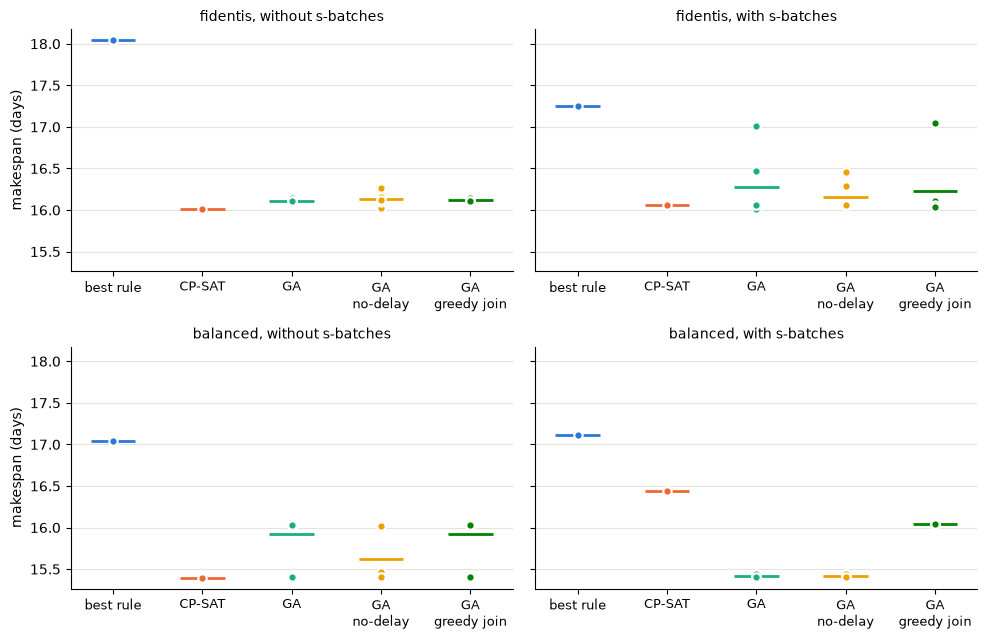

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharey=True)
for i, case in enumerate(CASES):
    for j, sb in enumerate((False, True)):
        ax = axes[i][j]
        for x, planner in enumerate(PLANNERS):
            vals = [r["makespan"] / DAY for r in ROWS
                    if r["case"] == case and r["s_batches"] == sb and r["planner"] == planner]
            ax.scatter([x] * len(vals), vals, s=36, color=COLORS[planner], edgecolor="white", linewidth=1.5,
                       zorder=3)
            ax.hlines(mean(vals), x - 0.25, x + 0.25, color=COLORS[planner], linewidth=2)
        ax.set_xticks(range(len(PLANNERS)), [p.replace("GA ", "GA\n") for p in PLANNERS], fontsize=9)
        ax.set_title(f"{case}, {'with' if sb else 'without'} s-batches", fontsize=10)
        ax.grid(axis="y", color="#e4e3dc", linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    axes[i][0].set_ylabel("makespan (days)")
fig.tight_layout()
plt.show()

## 3. Convergence

The GA's best makespan after the seeding (generation 0) and after every generation, with s-batches, one line per
seed. Generations take the same wall time per run only roughly (the decode time depends on the plan).

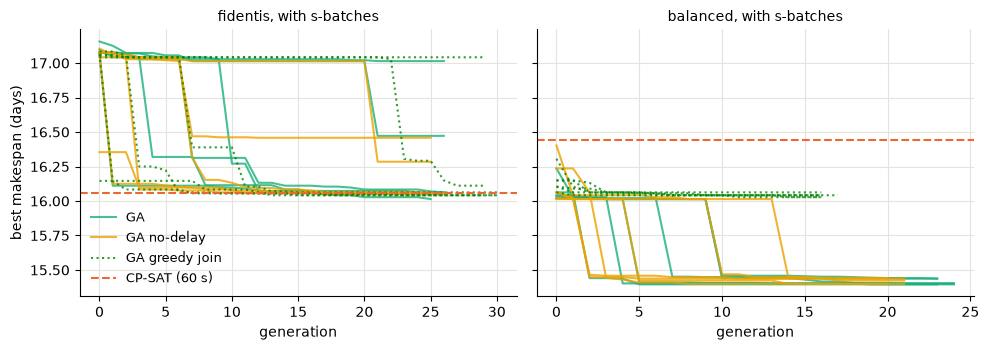

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, case in zip(axes, CASES, strict=True):
    for setting in SETTINGS:
        for k, r in enumerate(r for r in ROWS if r["case"] == case and r["s_batches"] and r["planner"] == setting):
            ax.plot(range(len(r["history"])), [v / DAY for v in r["history"]], color=COLORS[setting], linewidth=1.5,
                    linestyle=":" if setting == "GA greedy join" else "-",
                    alpha=0.8, label=setting if k == 0 else None)
    cp = next(r for r in ROWS if r["case"] == case and r["s_batches"] and r["planner"] == "CP-SAT")
    ax.axhline(cp["makespan"] / DAY, color=COLORS["CP-SAT"], linewidth=1.5, linestyle="--", label="CP-SAT (60 s)")
    ax.set_title(f"{case}, with s-batches", fontsize=10)
    ax.set_xlabel("generation")
    ax.grid(color="#e4e3dc", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("best makespan (days)")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Pareto fronts (NSGA-II)

NSGA-II over the same keys and decoder ([14](../math/14_genetic-algorithm.md) §3a), 120 s per front, with
s-batches. Left: makespan against overtime. Right: makespan against the total start deviation from the best rule
plan (stability, Wu et al. 1993): how far the plan must move away from a given plan to end earlier. Every point is
a feasible plan that no other found plan beats in both objectives.

loaded notebooks/results/09/fronts.json


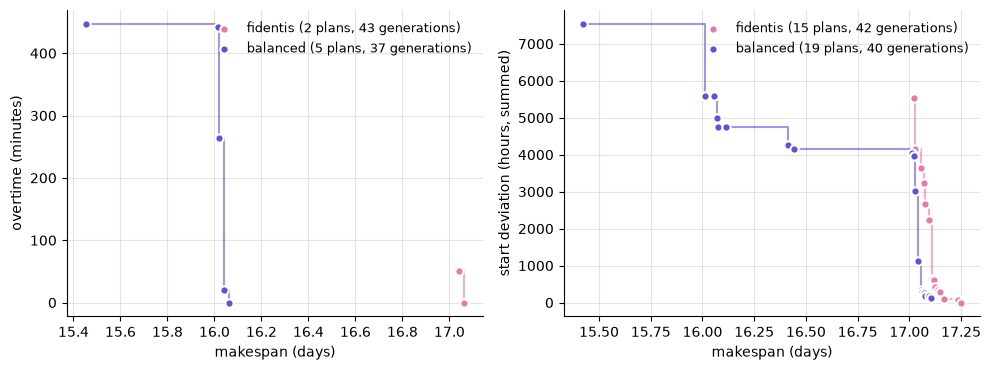

fidentis  overtime  [[24540, 50], [24570, 0]]
fidentis  stability [[24510, 331834], [24520, 249254], [24560, 218143], [24580, 193352], [24590, 160500], [24620, 133910], [24640, 38335], [24650, 36480], [24660, 24910], [24680, 19805], [24695, 16455], [24720, 5500], [24810, 5220], [24820, 4720], [24840, 0]]
balanced  overtime  [[22250, 447], [23060, 442], [23070, 264], [23100, 20], [23130, 0]]
balanced  stability [[22205, 452225], [23060, 335630], [23120, 334615], [23140, 299485], [23150, 285680], [23205, 285200], [23635, 256252], [23675, 249237], [24500, 241995], [24510, 237127], [24520, 181175], [24540, 67959], [24560, 21130], [24570, 16425], [24580, 16235], [24585, 11095], [24590, 11035], [24620, 10005], [24630, 7415]]


In [6]:
def fronts():
    jobs = [(c, k) for c in CASES for k in ("overtime", "stability")]
    with ProcessPoolExecutor(max_workers=4) as pool:
        return list(pool.map(front_run, *zip(*jobs, strict=True)))


FRONTS = cached("fronts", fronts)
assert all(f["feasible"] for f in FRONTS)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, kind, ylabel, scale in ((axes[0], "overtime", "overtime (minutes)", 1),
                                (axes[1], "stability", "start deviation (hours, summed)", 60)):
    for case, color in zip(CASES, ("#e87ba4", "#6250d6"), strict=True):  # instance colors, not planner colors
        f = next(f for f in FRONTS if f["case"] == case and f["kind"] == kind)
        xs, ys = [v[0] / DAY for v in f["front"]], [v[1] / scale for v in f["front"]]
        ax.step(xs, ys, where="post", color=color, linewidth=1.5, alpha=0.6)
        ax.scatter(xs, ys, s=36, color=color, edgecolor="white", linewidth=1.5, zorder=3,
                   label=f"{case} ({len(xs)} plans, {f['generations']} generations)")
    ax.set_xlabel("makespan (days)")
    ax.set_ylabel(ylabel)
    ax.grid(color="#e4e3dc", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()
for f in FRONTS:
    print(f"{f['case']:9} {f['kind']:9} {f['front']}")

## Findings (run of 2026-11-20, with the join key)

"GA" uses all five keys per operation; "GA no-delay" ignores the delay keys; "GA greedy join" ignores the join keys,
so every ready s-batch partner joins as in the rules ([14](../math/14_genetic-algorithm.md) §3).

**The join key.** On the balanced instance with s-batches the GA reaches 22170 to 22230 (mean 22193) against 23080 to
23130 with the greedy join and 23680 for CP-SAT: every seed is a working day better than the greedy join, and level
with the GA without s-batches (22180). With the greedy join a ready partner lengthens a batch and delays the lead's
successors; declining it removes that coupling. The GA then forms fewer batches (20 against 34) and saves fewer
setup minutes (335 against 545): it gives up batching where batching costs makespan. Without s-batches the join keys
have nothing to decide, and GA and greedy join give the same values. On fidentis with s-batches the join key brings
no clear gain (best 23060 against 23100, means 23443 against 23362, one seed of each stays a day behind).

**GA against CP-SAT.** At equal wall time (60 s; GA on one core, CP-SAT on 12 threads, hinted with the best rule
plan) the GA is level with CP-SAT on fidentis (with s-batches best 23060 against 23120; without 23080 to 23190
against 23060) and better on balanced with s-batches on every seed. On balanced without s-batches the seeds split
between about 22180 and 23080, one working day apart; CP-SAT reaches 22170. CP-SAT's value on balanced with
s-batches varies between runs (23270 in the run before, 23680 now: 12 threads are not deterministic).

**CP-SAT and its hint.** With the best rule plan as hint (MWKR, 24850) CP-SAT reaches 23120 on fidentis with
s-batches; notebook 08, hinted with SPT/ECT (30730), got 24500. The earlier finding "the GA beats CP-SAT with
s-batches" ([14](../math/14_genetic-algorithm.md) §5a) came mostly from the weak hint.

**s-batches and the makespan.** With the join key s-batches no longer lengthen the makespan, but they do not shorten
it either (balanced 22170 with against 22180 without; fidentis 23060 against 23080, a difference of minutes). They
save setup time (300 to 400 worker minutes in the GA's best plans), which shows in worker minutes, not in the
makespan: the makespan moves in steps of a working day.

**Delay window.** As before it brings no gain under makespan (balanced with s-batches: means 22193 with, 22209
without; fidentis: 23443 against 23272).

**Convergence.** The best makespan falls in steps of about a working day. On balanced with s-batches the greedy join
(dotted) never leaves the 16-day level, the GA with join keys drops to 15.4 days within 3 to 11 generations.

**Fronts** (NSGA-II, 120 s, with s-batches and join keys). Balanced, makespan against overtime: 22250 at 447 minutes
of overtime, 23100 at 20, 23130 at 0; a working day costs about 430 minutes of overtime. Fidentis: the run stayed on
the slow side (24540 at 50, 24570 at 0), worse than the run before with four keys (23200 at 10). Four seeds with and without join keys
(`notebooks/nsga_join_check.py`, [14](../math/14_genetic-algorithm.md) §5c): without them one seed of four reaches the
faster day (that 23200 was it), with them none; on the slower day the join keys need less overtime. So the seed, not
the join key: NSGA-II at 120 s mostly misses the day the BRKGA reaches in 60 s. Makespan against start deviation from the best rule plan:
within one day step the deviation falls to almost nothing for little makespan (fidentis 24720 at 5500, 24840 at 0;
balanced 24540 at 67959, 24630 at 7415), a day step moves most operations (balanced 22205 at 452225).

Limits: 6 seeds, wall-clock limits, makespan only (the thesis objective is lexicographic with tardiness), static
instances; one NSGA-II run per front (120 s). Own reading of the numbers.

## 5. The best GA plan

The first working days of the best GA plan on the fidentis instance with s-batches, per worker (one bar per batch,
labelled with all its orders).

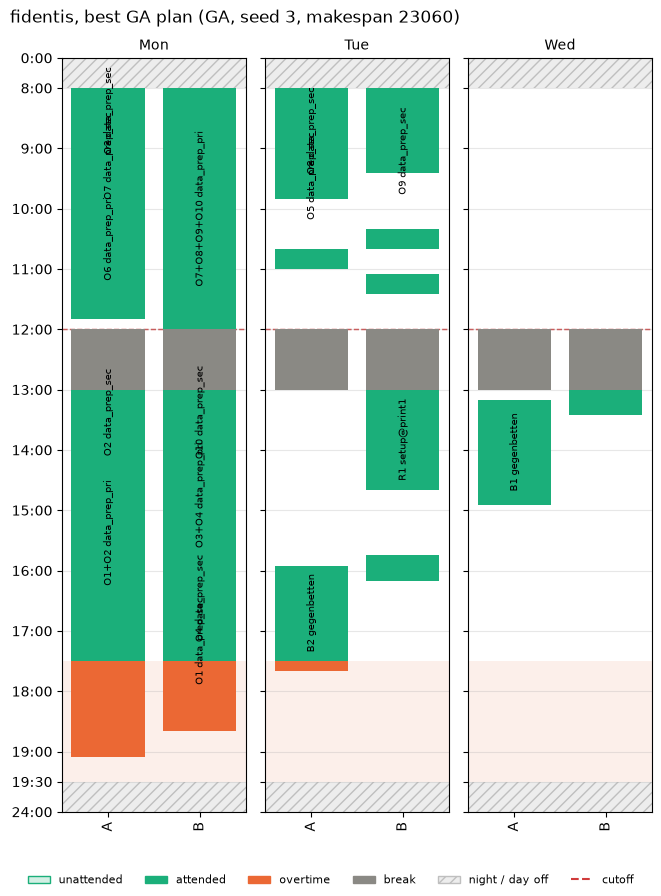

In [7]:
best = min((r for r in ROWS if r["case"] == "fidentis" and r["s_batches"] and "plan" in r),
           key=lambda r: r["makespan"])
plan = Schedule.model_validate(best["plan"])
plot_days(instance("fidentis", True), plan.assignments, plan.breaks, days=3, rows="workers",
          title=f"fidentis, best GA plan ({best['planner']}, seed {best['seed']}, makespan {best['makespan']})")
plt.show()

## 6. Rescheduling with arrivals

The comparison above plans once on a static instance. Here the planners work inside the DES
([05](../math/05_rescheduling-frozen-part.md)): orders are accepted over 10 working days (Poisson, 0.6 or 1.0 a
working day; the mill manages about 0.77, notebook 08), two orders are known at the start, due 10 working days after
acceptance. Nesting binds them at 12:00 on working days ([33](../math/33_order-release-interface.md)), all at once or under the
norm with a 3-day window and the arrival rate as forecast. Durations are disturbed (sigma 0.2, keyed per operation, the
same for every planner of a seed). Between nesting times the plan is only repaired (shifted); at every nesting time
with new orders the planner reschedules completely from the snapshot. Disturbances alone trigger no rescheduling, so
the comparison is about placing arrivals.

All planners of a seed start from the same CP-SAT plan of the first orders. Objective of CP-SAT and the GA: the
worker objective of the experiments (tardiness, then the cutoff buffer of 60 minutes, overtime, breaks, activity
clock; [06](../math/06_due-dates.md)). Effort per rescheduling: CP-SAT one thread, 5 deterministic seconds per level,
as in the experiments; the GA a fixed number of generations (both reproducible); the rule SPT/ECT. 4 seeds.

In [8]:
RESCHED_DIGEST = hashlib.sha256(repr((FIDENTIS.model_dump_json(), RATES, WINDOWS, RESCHED_PLANNERS,
                                       list(RESCHED_SEEDS), GA_GENERATIONS)).encode()).hexdigest()[:12]


def rescheduling():
    jobs = [(rate, w, pl, seed, GA_GENERATIONS) for rate in RATES for w in WINDOWS for pl in RESCHED_PLANNERS
            for seed in RESCHED_SEEDS]
    with ProcessPoolExecutor(max_workers=6) as pool:
        return list(pool.map(resched_run, *zip(*jobs, strict=True)))


EPISODES = cached("rescheduling", rescheduling, RESCHED_DIGEST)
print(f"{'rate':>4} {'release':8} {'planner':7} {'orders':>6} {'tardy':>5} {'tardy d':>7} {'overtime':>8} "
      f"{'makespan':>8} {'resched':>7} {'s/call':>6}")
for rate in RATES:
    for release in ("bind all", *(f"norm {w} d" for w in WINDOWS if w)):
        for pl in RESCHED_PLANNERS:
            es = [e for e in EPISODES if (e["rate"], e["release"], e["planner"]) == (rate, release, pl)]
            calls = sum(e["reschedulings"] for e in es)
            print(f"{rate:4} {release:8} {pl:7} {mean(e['orders'] for e in es):6.1f} "
                  f"{mean(e['tardy_orders'] for e in es):5.1f} {mean(e['tardy_days'] for e in es):7.1f} "
                  f"{mean(e['overtime'] for e in es):8.0f} {mean(e['makespan'] for e in es) / DAY:8.1f} "
                  f"{calls / len(es):7.1f} {sum(e['planner_time'] for e in es) / max(calls, 1):6.1f}")

rate release  planner orders tardy tardy d overtime makespan resched s/call
 0.6 bind all rule       6.5   3.2    14.2       38     19.5     3.5    0.0
 0.6 bind all CP-SAT     6.5   3.8    19.2       15     18.7     3.5   53.7
 0.6 bind all GA         6.5   1.5     2.5       32     16.1     3.5   24.7
 0.6 norm 3 d rule       6.5   2.8     8.5       48     21.0     4.2    0.0
 0.6 norm 3 d CP-SAT     6.5   4.0     8.8       32     20.2     4.2   20.2
 0.6 norm 3 d GA         6.5   2.8     6.0       27     19.8     4.2   21.7
 1.0 bind all rule       8.5   5.5    40.5       62     25.1     4.2    0.0
 1.0 bind all CP-SAT     8.5   7.2    35.0       56     25.4     4.2  104.3
 1.0 bind all GA         8.5   5.5    16.8       56     21.8     4.2   32.8
 1.0 norm 3 d rule       8.5   5.0    36.2       57     28.9     5.0    0.0
 1.0 norm 3 d CP-SAT     8.5   6.2    32.8       49     27.9     5.0   32.0
 1.0 norm 3 d GA         8.5   5.0    27.5       38     26.4     5.0   22.3


Tardy days per seed (dots, one colour per planner; a line joins the planners of one seed) and their mean (bar),
per arrival rate and release.

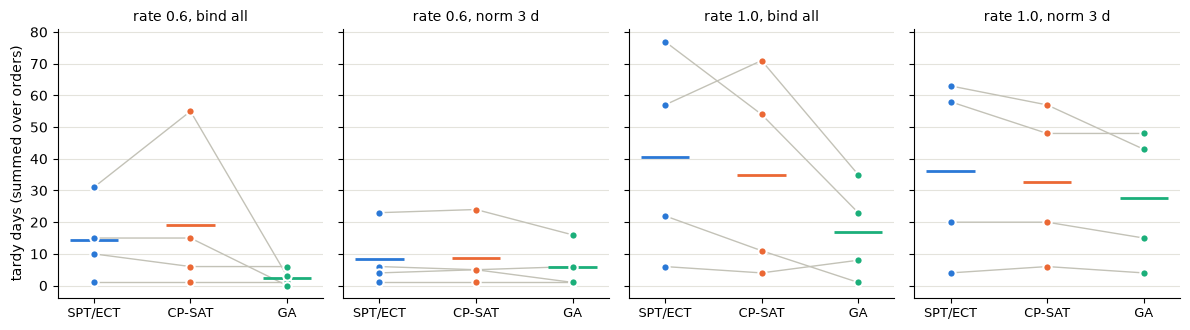

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
panels = [(rate, release) for rate in RATES for release in ("bind all", *(f"norm {w} d" for w in WINDOWS if w))]
for ax, (rate, release) in zip(axes, panels, strict=True):
    for seed in RESCHED_SEEDS:
        ys = [next(e["tardy_days"] for e in EPISODES if (e["rate"], e["release"], e["planner"], e["seed"])
                   == (rate, release, pl, seed)) for pl in RESCHED_PLANNERS]
        ax.plot(range(len(ys)), ys, color="#c3c2b7", linewidth=1, zorder=1)
    for x, pl in enumerate(RESCHED_PLANNERS):
        ys = [e["tardy_days"] for e in EPISODES if (e["rate"], e["release"], e["planner"]) == (rate, release, pl)]
        color = COLORS["best rule" if pl == "rule" else pl]
        ax.scatter([x] * len(ys), ys, s=36, color=color, edgecolor="white", linewidth=1.5, zorder=3)
        ax.hlines(mean(ys), x - 0.25, x + 0.25, color=color, linewidth=2, zorder=2)
    ax.set_xticks(range(len(RESCHED_PLANNERS)), ["SPT/ECT", "CP-SAT", "GA"], fontsize=9)
    ax.set_title(f"rate {rate}, {release}", fontsize=10)
    ax.grid(axis="y", color="#e4e3dc", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("tardy days (summed over orders)")
fig.tight_layout()
plt.show()

**Findings (run of 2026-11-22).** Means over 4 seeds (tardy days summed over orders):

| rate | release | SPT/ECT | CP-SAT | GA |
|---|---|---|---|---|
| 0.6 | bind all | 12.8 | 5.5 | 1.8 |
| 0.6 | norm 3 d | 9.0 | 8.8 | 4.0 |
| 1.0 | bind all | 41.5 | 50.0 | 17.8 |
| 1.0 | norm 3 d | 36.2 | 38.2 | 28.8 |

- **The GA has the fewest tardy days in every setting** and on 13 of 16 seed and setting pairs at most as many as
  CP-SAT; above capacity with bind all it cuts them to less than half of both others (17.8 against 41.5 and 50.0).
  Its makespan is also shortest in every setting (16.1 to 26.5 days against 18.9 to 28.9).
- **CP-SAT is not better than the rule above capacity.** With 5 deterministic seconds per level (as in the
  experiments) it never hit the 120 s wall clock, so the budget, not a failure, stopped it; per call it used 27 to 176
  s of wall time, the GA 35 to 57 s (30 generations). At 0.6 bind all it beats the rule (5.5 against 12.8).
- **The norm helps the rule, not the optimizers.** It lowers the rule's tardy days (12.8 to 9.0, 41.5 to 36.2) but
  raises the GA's (1.8 to 4.0, 17.8 to 28.8): a planner that sequences well gains more from seeing the orders early
  than from a short queue.
- **Overtime** stays small for all (means 20 to 90 minutes over a run); no planner is consistently higher (the GA
  more with bind all, less under the norm).

Limits: 4 seeds, 4 to 11 orders per episode (seed 3 at rate 1.0 only 4), one CP-SAT budget, the rule optimizes no
objective; disturbances are only repaired. Own reading of the numbers.

## 7. The plan over time

The DES records the plan at every time point it changes (repair or rescheduling) with the metrics of that plan
([23](../math/23_metrics.md) (M10)). Here for rate 1.0 (above the mill's capacity), seeds 1 and 4, both releases and
all three planners; the animation shows seed 1 with bind all, the GA against CP-SAT (the setting where they differ
most). One frame per day at 12:01, just after the nesting batch and its rescheduling. Grey: finished operations as
realized; blue: planned; orange: planned after the order's due date (red tick); the line is the current time. A
print, milling or oven run shows in the row of every order it serves. An order gets its row filled when it arrives.

In [10]:
HISTORY_RUNS = [(1.0, w, pl, seed) for w in WINDOWS for seed in (1, 4) for pl in RESCHED_PLANNERS]
ANIMATED = [(1.0, None, "GA", 1), (1.0, None, "CP-SAT", 1)]
HISTORY_DIGEST = hashlib.sha256(repr((RESCHED_DIGEST, HISTORY_RUNS, ANIMATED)).encode()).hexdigest()[:12]


def histories():
    jobs = [(rate, w, pl, seed, GA_GENERATIONS, True) for rate, w, pl, seed in HISTORY_RUNS]
    with ProcessPoolExecutor(max_workers=6) as pool:
        runs = list(pool.map(resched_run, *zip(*jobs, strict=True)))
    out = []
    for key, r in zip(HISTORY_RUNS, runs, strict=True):
        keep = {"rate": r["rate"], "release": r["release"], "planner": r["planner"], "seed": r["seed"],
                "series": [[h["t"], h["type"], h["metrics"]] for h in r["history"]]}
        if key in ANIMATED:  # the change sets without the break lists (they repeat in every record)
            keep |= {"history": [{"t": h["t"], "changed": h["changed"]} for h in r["history"]],
                     "instance": r["instance"], "realized": r["realized"]}
        out.append(keep)
    return out


HISTORIES = cached("history", histories, HISTORY_DIGEST)
print(len(HISTORIES), "episodes")

12 episodes


In [11]:
runs = [next(h for h in HISTORIES if (h["rate"], None if h["release"] == "bind all" else 3, h["planner"],
                                      h["seed"]) == key) for key in ANIMATED]
ci_h = compile_instance(Instance.model_validate(runs[0]["instance"]))
realized = [{(k, j): (s, e) for k, j, s, e in r["realized"]} for r in runs]
t_max = max(e for real in realized for s, e in real.values())
frames = list(range(241, t_max + DAY, DAY))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)


def frame(t):
    for ax, r, real in zip(axes, runs, realized, strict=True):
        ax.clear()
        plot_plan_state(ci_h, plan_at(r["history"], t), real, t, ax, t_max)
        ax.set_title(f"{r['planner']}, day {t / DAY:.1f}", fontsize=10, loc="left")
    fig.tight_layout()


anim = FuncAnimation(fig, frame, frames=frames, interval=500)
plt.close(fig)
HTML(anim.to_jshtml())

Planned tardy days and planned makespan of the plan in force, over the run (a step at every repair or
rescheduling); dots mark the reschedulings at nesting times. Rate 1.0, one column per release and seed.

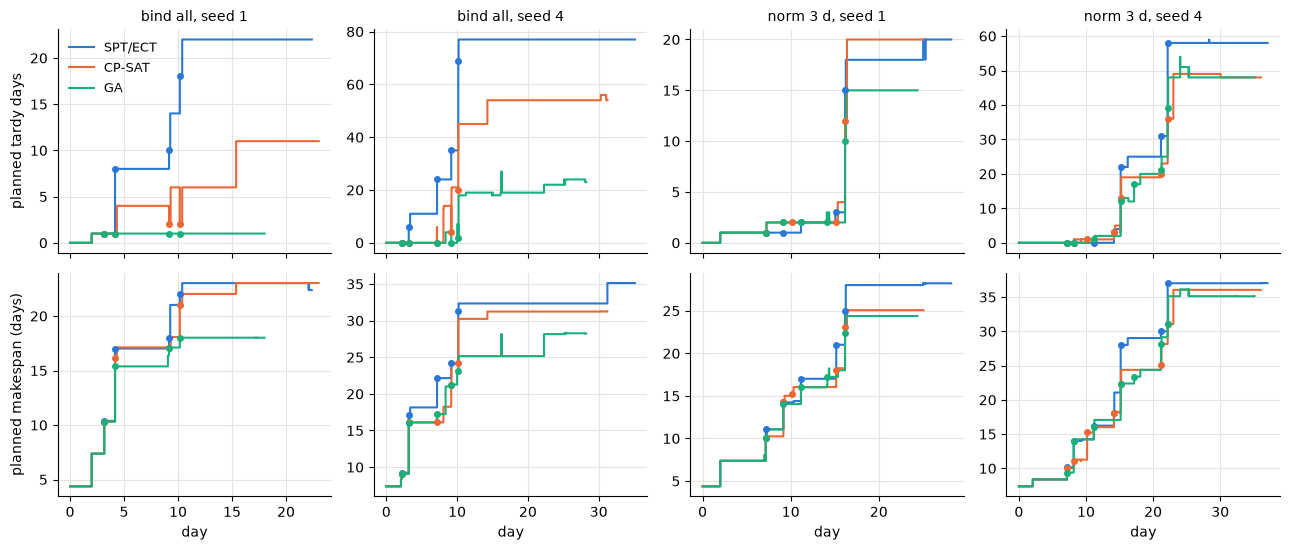

In [12]:
panels = [(release, seed) for release in ("bind all", "norm 3 d") for seed in (1, 4)]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharex="col")
for j, (release, seed) in enumerate(panels):
    for pl in RESCHED_PLANNERS:
        h = next(h for h in HISTORIES if (h["release"], h["seed"], h["planner"]) == (release, seed, pl))
        ts = [t / DAY for t, _, _ in h["series"]]
        color = COLORS["best rule" if pl == "rule" else pl]
        for i, metric in enumerate(("tardy_days", "makespan")):
            ys = [m[metric] / (DAY if metric == "makespan" else 1) for _, _, m in h["series"]]
            axes[i][j].plot(ts, ys, drawstyle="steps-post", color=color, linewidth=1.5,
                            label="SPT/ECT" if pl == "rule" else pl)
            replans = [(t, y) for (t, kind, _), y in zip(h["series"], ys, strict=True) if kind == "REPLAN"]
            axes[i][j].scatter([t / DAY for t, _ in replans], [y for _, y in replans], s=16, color=color, zorder=3)
    axes[0][j].set_title(f"{release}, seed {seed}", fontsize=10)
    axes[1][j].set_xlabel("day")
    for ax in axes[:, j]:
        ax.grid(color="#e4e3dc", linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
axes[0][0].set_ylabel("planned tardy days")
axes[1][0].set_ylabel("planned makespan (days)")
axes[0][0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

**What the plan history shows** (rate 1.0, seeds 1 and 4):

- **Seed 1, bind all:** the GA's plan reaches 1 planned tardy day at day 2 and keeps it to the end. The rule's
  climbs with every binding to 22 by day 10.4. CP-SAT's reschedulings lower it (to 3 at days 9.2 and 10.2), but the
  repairs right after push it up again (9 at day 10.2, 14 at day 15.4, 18 at day 17.4): disturbances trigger no
  rescheduling here (§6), so a tight plan drifts and nothing re-sequences it. The GA's plan absorbs the same
  disturbances.
- **Under the norm the planners stay close until the late bindings** (planned tardy days at most 3 up to day 14 to
  15), when the held-back orders arrive together; from then on the GA's plan has the fewest (seed 1 day 16.2: rule 15,
  CP-SAT 11, GA 9; seed 4 at the end: 58, 55, 36).
- **Animation (seed 1, bind all):** at the end only O2 finished late with the GA (realized tardy days 1); with
  CP-SAT seven of eight orders did.

Own reading of 4 episodes per planner; the history is the plan in force, not the realized schedule (M10).

## 8. Rescheduling on drift

In §6 and §7 only nesting times trigger a complete rescheduling; in between the repair shifts operations right, and a
tight plan drifts (§7, CP-SAT). Here the policy also reschedules when the repaired plan's tardy days (missed
cutoffs, [06](../math/06_due-dates.md)) deviate from the last rescheduled plan's by more than 1
(`ReschedulingPolicy(objective=TOTAL_TARDINESS, max_objective_change=1)`, [05](../math/05_rescheduling-frozen-part.md)
§3). Rate 1.0 (where the drift showed), both releases, the same 4 seeds and budgets as §6; compared with §6.

In [13]:
TRIGGER = 1  # tardy days of drift tolerated
TRIGGER_RUNS = [(1.0, w, pl, seed) for w in WINDOWS for pl in RESCHED_PLANNERS for seed in RESCHED_SEEDS]
TRIGGER_DIGEST = hashlib.sha256(repr((RESCHED_DIGEST, TRIGGER_RUNS, TRIGGER)).encode()).hexdigest()[:12]


def triggered():
    jobs = [(rate, w, pl, seed, GA_GENERATIONS, False, TRIGGER) for rate, w, pl, seed in TRIGGER_RUNS]
    with ProcessPoolExecutor(max_workers=6) as pool:
        return list(pool.map(resched_run, *zip(*jobs, strict=True)))


TRIGGERED = cached("trigger", triggered, TRIGGER_DIGEST)
print(f"{'release':8} {'planner':7} {'tardy d':>15} {'tardy orders':>13} {'resched':>9} {'planner s':>11}")
print(f"{'':16} {'nesting / +drift':>16}")
for release in ("bind all", "norm 3 d"):
    for pl in RESCHED_PLANNERS:
        base = [e for e in EPISODES if (e["rate"], e["release"], e["planner"]) == (1.0, release, pl)]
        trig = [e for e in TRIGGERED if (e["release"], e["planner"]) == (release, pl)]
        cols = [(mean(e[m] for e in base), mean(e[m] for e in trig))
                for m in ("tardy_days", "tardy_orders", "reschedulings", "planner_time")]
        print(f"{release:8} {pl:7} " + " ".join(f"{a:7.1f}/{b:<7.1f}" for a, b in cols))

release  planner         tardy d  tardy orders   resched   planner s
                 nesting / +drift
bind all rule       40.5/39.5        5.5/6.0         4.2/8.2         0.0/0.1    
bind all CP-SAT     35.0/25.8        7.2/6.2         4.2/68.5      443.3/4065.2 
bind all GA         16.8/4.8         5.5/2.8         4.2/67.2      139.6/2353.7 
norm 3 d rule       36.2/32.8        5.0/5.0         5.0/7.0         0.0/0.1    
norm 3 d CP-SAT     32.8/19.0        6.2/5.0         5.0/187.2     160.0/4243.5 
norm 3 d GA         27.5/19.8        5.0/4.8         5.0/30.8      111.5/740.2  


Tardy days per seed without (left of each pair) and with the drift trigger (right), joined per seed.

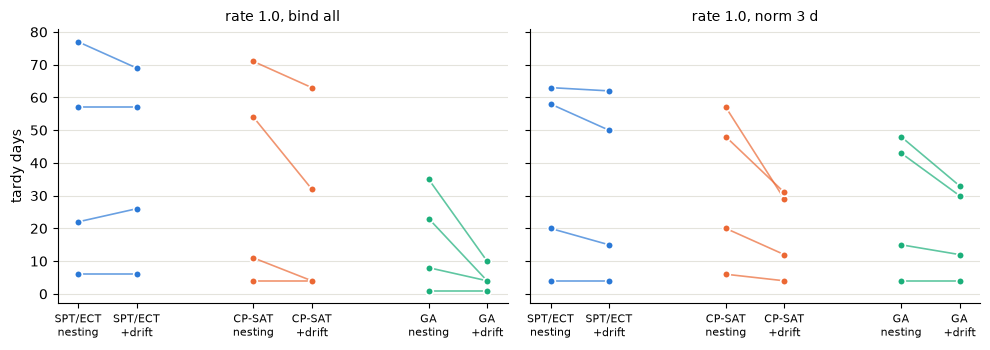

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, release in zip(axes, ("bind all", "norm 3 d"), strict=True):
    for x, pl in enumerate(RESCHED_PLANNERS):
        color = COLORS["best rule" if pl == "rule" else pl]
        for seed in RESCHED_SEEDS:
            a = next(e["tardy_days"] for e in EPISODES
                     if (e["rate"], e["release"], e["planner"], e["seed"]) == (1.0, release, pl, seed))
            b = next(e["tardy_days"] for e in TRIGGERED if (e["release"], e["planner"], e["seed"]) == (release, pl, seed))
            ax.plot([3 * x, 3 * x + 1], [a, b], color=color, linewidth=1.2, alpha=0.7)
            ax.scatter([3 * x, 3 * x + 1], [a, b], s=30, color=color, edgecolor="white", linewidth=1.2, zorder=3)
    ax.set_xticks([t for x in range(3) for t in (3 * x, 3 * x + 1)],
                  [f"{n}\n{w}" for n in ("SPT/ECT", "CP-SAT", "GA") for w in ("nesting", "+drift")], fontsize=8)
    ax.set_title(f"rate 1.0, {release}", fontsize=10)
    ax.grid(axis="y", color="#e4e3dc", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("tardy days")
fig.tight_layout()
plt.show()